# Типология клиентской базы

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
sklearn.set_config(working_memory=256)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

ROOT = Path.cwd()
while not (ROOT / "CLAUDE.md").exists():
    ROOT = ROOT.parent
DATA, ART = ROOT / "data", ROOT / "artifacts"
sys.path.insert(0, str(ROOT / "src"))

from common import SEED
print("корень проекта:", ROOT, "| SEED =", SEED)

корень проекта: /home/user/uzcardacademy_homework6/third/seg-typology | SEED = 42


In [2]:
def art(rel, **kw):

    return pd.read_csv(ART / rel, **kw)

def img(rel, width=850):

    display(Image(filename=str(ART / rel), width=width))

## Подключение к базе

In [3]:
DB_OK = False
try:
    from common import connect, q
    engine = connect()
    with engine.connect() as conn:
        conn.exec_driver_sql("select 1")
    DB_OK = True
except Exception as e:
    print("база недоступна, работаем с выгрузками из data/:", type(e).__name__)
print("DB_OK =", DB_OK)

база недоступна, работаем с выгрузками из data/: OperationalError
DB_OK = False


# Этап 1. Данные и признаки
## Таблицы-источники

In [4]:
verdict = art("eda/tables_verdict.csv")
verdict[["table_name", "n_rows", "n_clients", "verdict", "evidence_code", "evidence"]]

,table_name,n_rows,n_clients,verdict,evidence_code,evidence
0,seg_balances,427598,20000.0,источник,E6-SOURCE,уникальных данных не найдено ни у одной другой таблицы: 1 строка = клиент × month_star...
1,seg_customers,20000,20000.0,источник,E6-SOURCE,"уникальных данных не найдено ни у одной другой таблицы: 1 строка = 1 клиент, 20 000 ст..."
2,seg_customers_360,20000,20000.0,мусор,E4-DERIVED,агрегированная витрина: все проверенные колонки выводятся из источников region = seg_c...
3,seg_products,29983,15844.0,источник,E6-SOURCE,уникальных данных не найдено ни у одной другой таблицы: 1 строка = событие; клиент × o...
4,seg_revenue_monthly,427598,20000.0,источник,E6-SOURCE,уникальных данных не найдено ни у одной другой таблицы: 1 строка = клиент × month_star...
5,seg_rfm_old,18966,18966.0,мусор,E3-READY,чужой готовый расчёт в колонках: recency_days;frequency;monetary. Воспроизводится точн...
6,seg_tariff_current,1,NaN,справочник,E5-DICT,"клиентской колонки нет, 1 строк(и) — присоединять не к чему; используется как контекст..."
7,seg_temp,0,NaN,мусор,E0-EMPTY,"таблица пуста: ни одной строки, назначение не восстановимо"
8,seg_transactions,12136132,19755.0,источник,E6-SOURCE,уникальных данных не найдено ни у одной другой таблицы: 1 строка = событие; клиент × t...
9,seg_transactions_archive,2718367,15962.0,мусор,E1-DUP,схема совпадает с seg_transactions; 2 639 168 из 2 639 168 различных строк присутствую...


In [5]:
if DB_OK:
    sources = verdict.loc[verdict.verdict == "источник", "table_name"].tolist()
    with engine.connect() as conn:
        live = {t: q(conn, f"select count(*) as n from {t}")["n"].iloc[0] for t in sources}
    check = verdict.set_index("table_name").loc[sources, ["n_rows"]].assign(n_rows_live=pd.Series(live))
    display(check)
else:
    print("пропущено: база недоступна")

пропущено: база недоступна


## Старая CRM-сегментация

In [6]:
legacy = art("eda/legacy_segments_check.csv")
legacy.groupby(["segment_source", "metric_ru"])[["eta_squared", "kruskal_p", "effect_verdict"]].first()

eta_squared  kruskal_p effect_verdict
segment_source metric_ru                                                           
crm_segment    доля наличных в расходе           0.000008   0.367928   различий нет
               оборот по расходным операциям    -0.000135   0.958393   различий нет
               средний остаток                   0.000014   0.350011   различий нет
               число подключённых продуктов      0.000062   0.237163   различий нет

## Доходность

In [7]:
art("eda/profile_revenue_derivation.csv")[["component", "source_ru", "n_rows", "pearson_corr", "implied_rate_pct", "is_deterministic"]]

,component,source_ru,n_rows,pearson_corr,implied_rate_pct,is_deterministic
0,interchange_uzs,оборот по карте (pos + ecom),401945,1.0,0.8,True
1,transfer_fee_uzs,входящие переводы p2p,216522,1.0,0.1,True
2,atm_cost_uzs,снятия в банкомате,353142,1.0,0.2,True
3,float_income_uzs,средний остаток за месяц,427598,1.0,0.5,True


## Сезонность

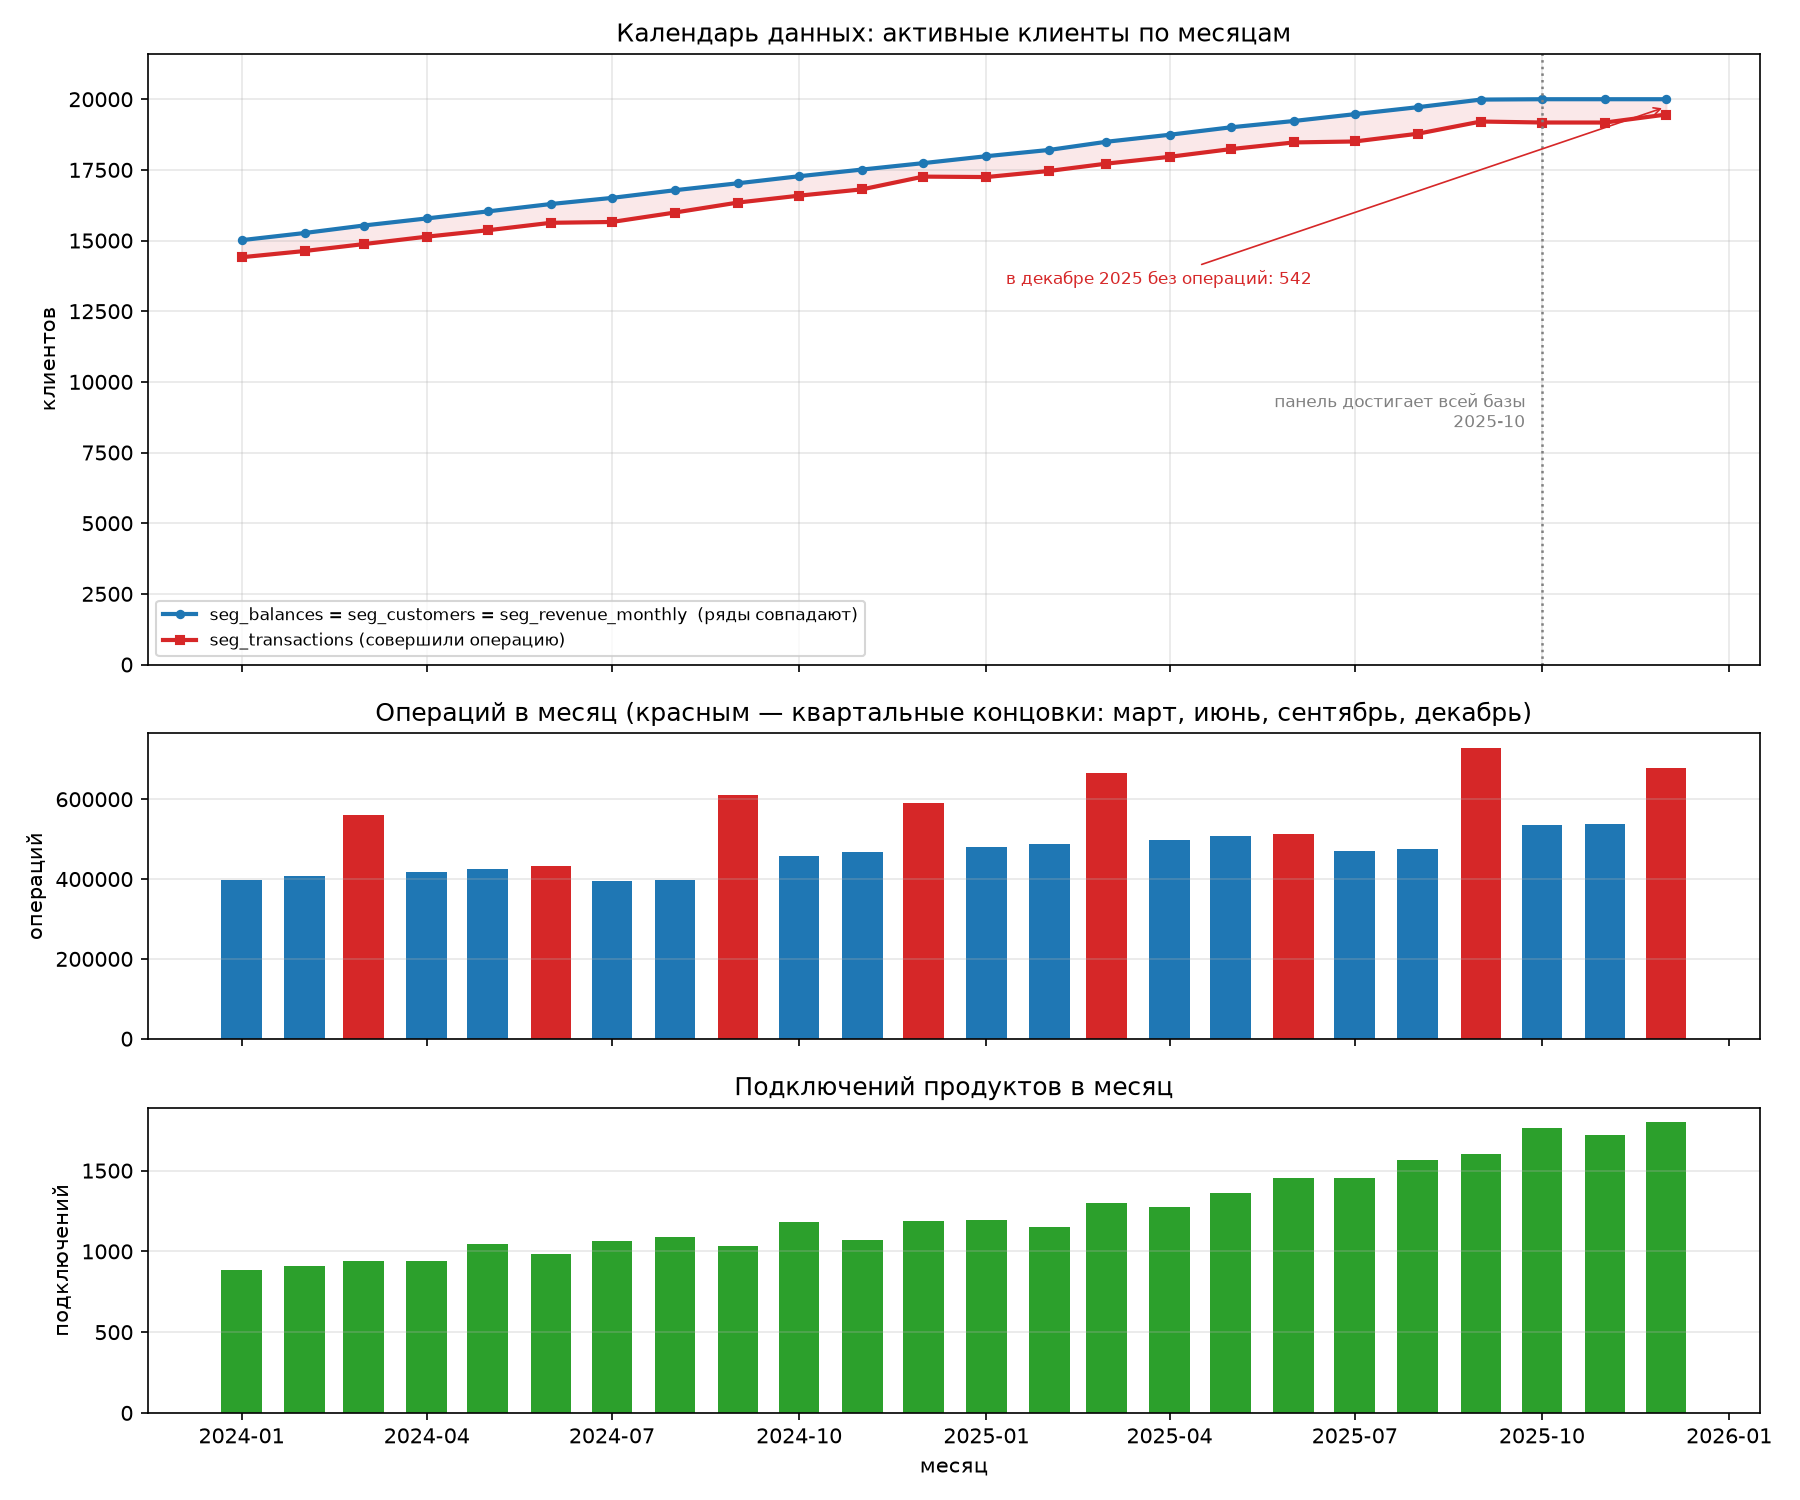

In [8]:
img("eda/data_calendar.png")

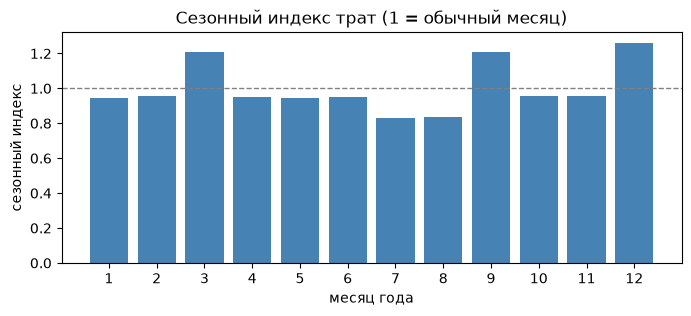

In [9]:
si = art("eda/seasonal_index.csv")
si = si[pd.to_numeric(si["moy"], errors="coerce").between(1, 12)]
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(si["moy"].astype(int), si["index"], color="steelblue")
ax.axhline(1, color="grey", lw=1, ls="--")
ax.set(xlabel="месяц года", ylabel="сезонный индекс", title="Сезонный индекс трат (1 = обычный месяц)")
ax.set_xticks(range(1, 13))
plt.show()

## Длина истории и стаж

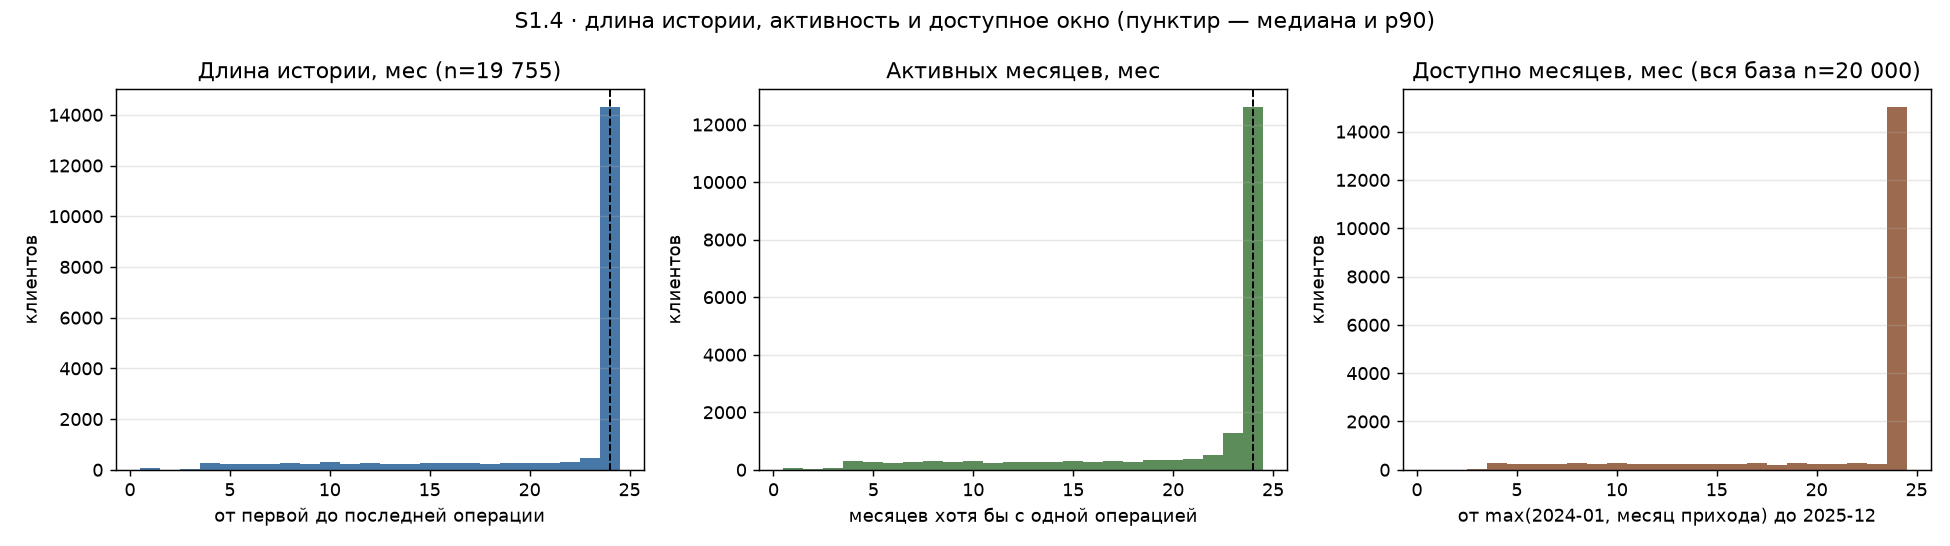

In [10]:
img("eda/tenure_distribution.png", width=750)

## Стационарность поведения

In [11]:
drift = art("eda/drift_stats.csv")
drift[drift["section"].isin(["охват", "доля дрейфующих", "разладка"])][["section", "metric", "value", "note"]]

,section,metric,value,note
0,охват,клиентов в базе,20000.000000,D-019
1,охват,клиентов с операциями,19755.000000,NaN
2,охват,оценено на дрейф (>= 6 активных месяцев),19001.000000,доля базы 0.950050
3,охват,не оценено: история короче 6 месяцев,754.000000,доля базы 0.049950 с учётом 245 клиентов без операций
19,доля дрейфующих,"десезонализованные, свой порог",0.182990,3 477 клиентов из 19 001 оценённых; доля базы 0.173850
20,доля дрейфующих,"сырые, свой порог",0.182780,3 473 клиентов из 19 001 оценённых; доля базы 0.173650
21,доля дрейфующих,"десезонализованные, общий порог",0.142256,2 703 клиентов из 19 001 оценённых; доля базы 0.135150
22,доля дрейфующих,"сырые, общий порог",0.139677,2 654 клиентов из 19 001 оценённых; доля базы 0.132700
23,доля дрейфующих,"избыток над ожиданием, клиентов",1576.900000,доля базы 0.078845; столько клиентов дрейфуют сверх шума
24,доля дрейфующих,"избыток над ожиданием, п.п.",8.299037,NaN


In [12]:
art("eda/icc_by_feature.csv")[["human", "n_clients", "icc", "reading"]]

,human,n_clients,icc,reading
0,расходный оборот,12604,0.889786,описывает клиента
1,число операций,12604,0.791675,описывает клиента
2,доля наличных,11985,0.405306,"описывает месяц не меньше, чем клиента"
3,доля онлайна,10783,0.612182,описывает клиента умеренно
4,средний остаток,12604,0.847589,описывает клиента
5,доля топ-категории,10783,0.409170,"описывает месяц не меньше, чем клиента"


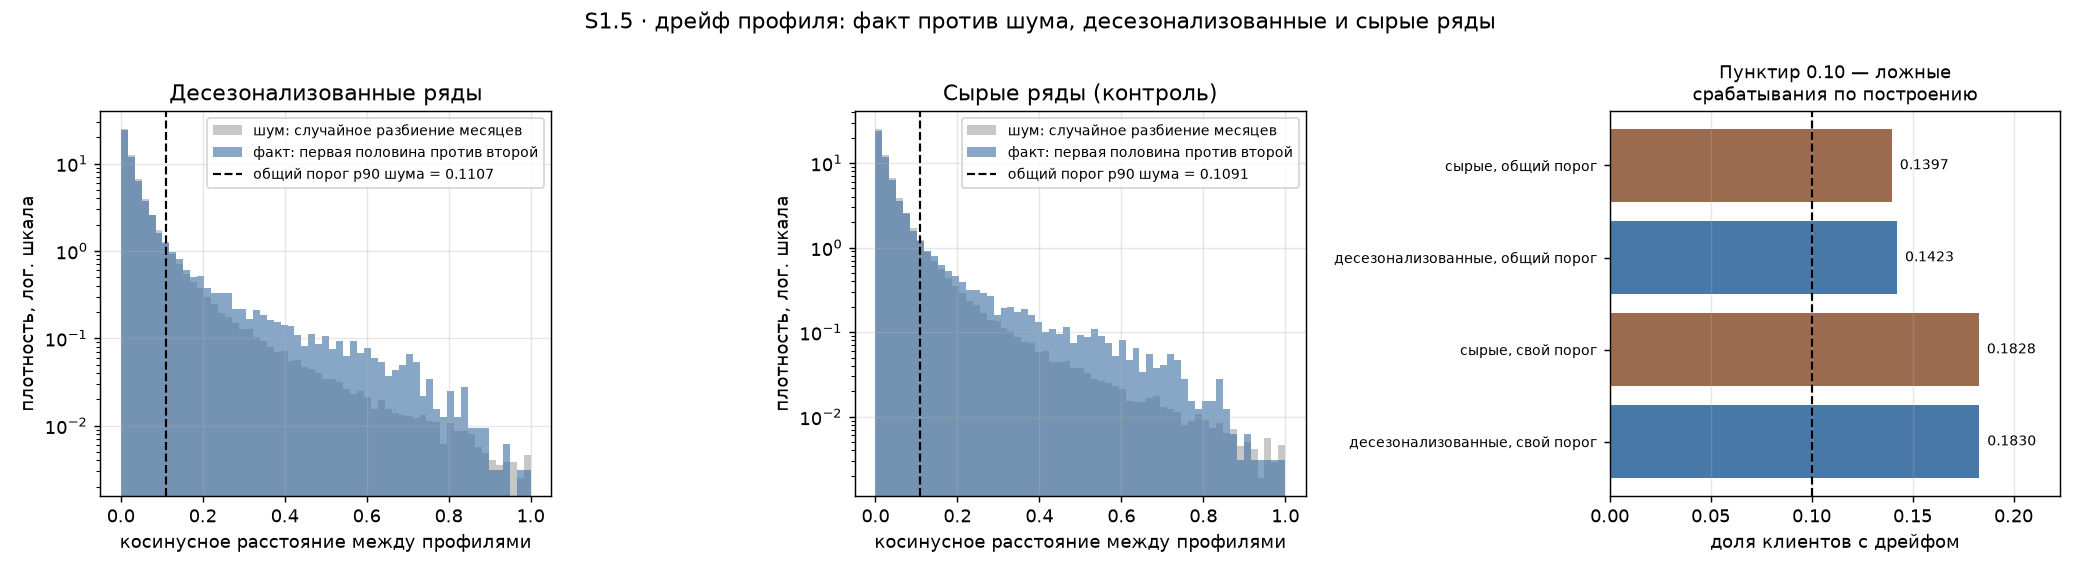

In [13]:
img("eda/drift_distribution.png", width=750)

## Выбор окна наблюдения

In [14]:
win = art("eda/window_choice_matrix.csv")
cols = ["key", "months_from", "months_to", "coverage_available", "reliability_median",
        "share_break_inside", "eta2_tenure_months", "conditions_passed", "passes_all", "chosen"]
win[cols]

,key,months_from,months_to,coverage_available,reliability_median,share_break_inside,eta2_tenure_months,conditions_passed,passes_all,chosen
0,W3_ds,2025-07,2025-09,1.00000,0.701898,0.00050,0.011468,2,False,False
1,W3_raw,2025-07,2025-09,1.00000,0.704217,0.00050,0.011056,2,False,False
2,W6_ds,2025-04,2025-09,0.97355,0.780402,0.00885,0.002058,3,False,False
3,W6_raw,2025-04,2025-09,0.97355,0.781695,0.00885,0.002003,3,False,False
4,W9_ds,2025-01,2025-09,0.93710,0.826099,0.01565,0.000872,4,True,True
5,W9_raw,2025-01,2025-09,0.93710,0.827185,0.01565,0.000695,4,True,False
6,W12_ds,2024-10,2025-09,0.89920,0.853259,0.02210,0.000528,3,False,False
7,W12_raw,2024-10,2025-09,0.89920,0.854068,0.02210,0.000537,3,False,False
8,W21_ds,2024-01,2025-09,0.78910,0.893468,0.02760,-0.000079,3,False,False
9,W21_raw,2024-01,2025-09,0.78910,0.893987,0.02760,-0.000081,3,False,False


выбрано окно W9_ds: W = 2025-01 … 2025-09, V = три месяца после W (2025-10 … 2025-12)


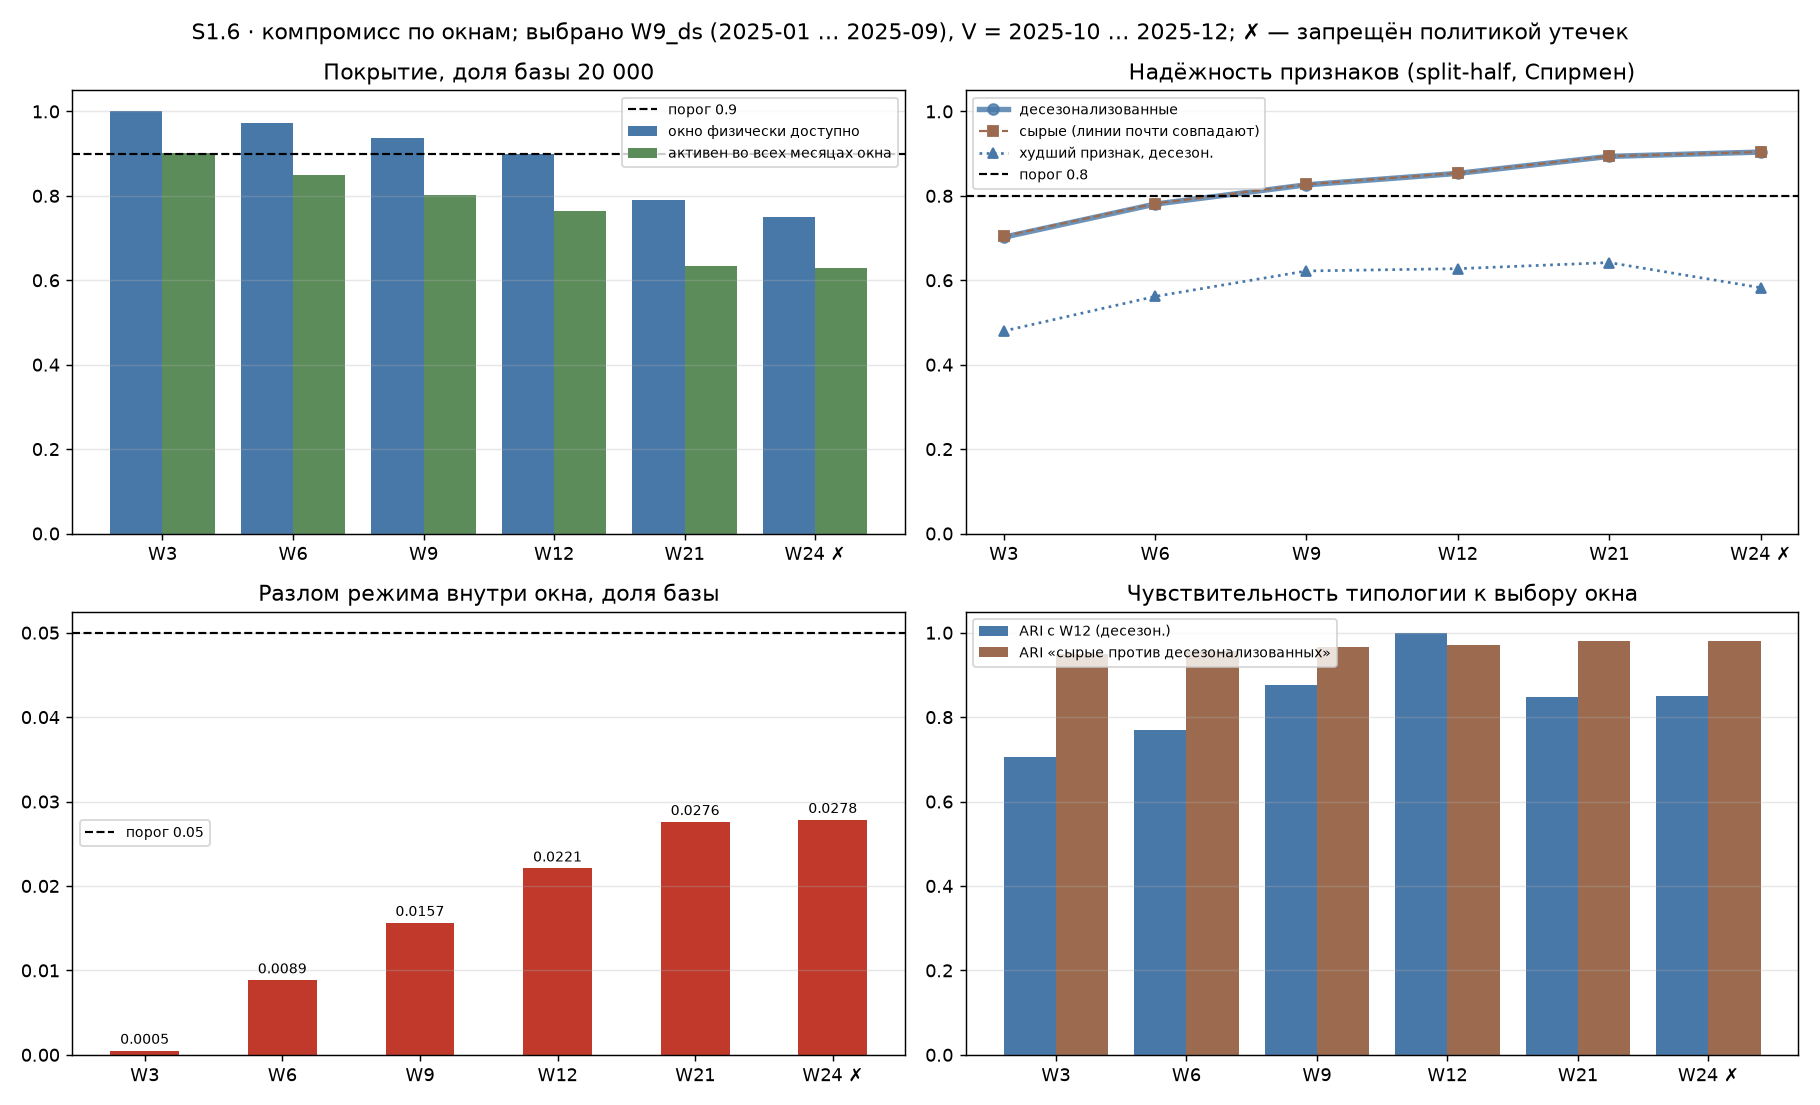

In [15]:
chosen = win.loc[win["chosen"], ["key", "months_from", "months_to"]].iloc[0]
print(f"выбрано окно {chosen.key}: W = {chosen.months_from} … {chosen.months_to}, V = три месяца после W (2025-10 … 2025-12)")
img("eda/window_tradeoff.png", width=750)

## Обучающая совокупность

In [16]:
fw = pd.read_parquet(DATA / "features_wide.parquet")
cold = pd.read_parquet(DATA / "cold_start_clients.parquet")
silent = pd.read_parquet(DATA / "silent_in_window_clients.parquet")
modeling = set(fw.loc[fw["diag__in_modeling_set"], "customer_id"])

groups = pd.Series({"в обучении (modeling_set)": len(modeling),
                    "холодный старт": len(cold), "молчащие в окне": len(silent)})
display(groups.to_frame("клиентов").assign(доля_базы=lambda d: d["клиентов"] / 20000))
print("сумма групп:", groups.sum())
print("пересечения пусты:", not (modeling & set(cold.customer_id)) and not (modeling & set(silent.customer_id))
      and not (set(cold.customer_id) & set(silent.customer_id)))

,клиентов,доля_базы
в обучении (modeling_set),18370,0.9185
холодный старт,1258,0.0629
молчащие в окне,372,0.0186


сумма групп: 20000
пересечения пусты: True


## Признаки

In [17]:
fba = art("features/features_by_axis.csv")
fba[["признак", "ось", "смысл простыми словами"]]

,признак,ось,смысл простыми словами
0,log_amt_spend_pm,A интенсивность,"Сколько денег клиент тратит картой за месяц, когда он вообще платит. Логарифм нужен, ч..."
1,log_n_txn_pm,A интенсивность,Как часто клиент платит за месяц. Вместе с предыдущим отвечает на вопрос «много мелких...
2,cat_share_grocery,B структура трат,"Какая доля трат уходит на продукты. Единственная категория, которая есть почти у всех,..."
3,cat_share_marketplace,B структура трат,"Какая доля трат уходит на маркетплейсы. У 63% клиентов здесь ноль, поэтому признак отв..."
4,cat_share_transport,B структура трат,"Какая доля трат уходит на транспорт: такси, проезд, каршеринг. У 53% клиентов здесь но..."
5,cat_share_services,B структура трат,"Какая доля трат уходит на услуги и подписки. У 50% клиентов здесь ноль, поэтому призна..."
6,cat_share_fuel,B структура трат,Какая доля трат уходит на заправки — по сути признак «есть ли машина». У 59% клиентов ...
7,cat_share_utilities,B структура трат,"Какая доля трат уходит на коммунальные платежи. У 53% клиентов здесь ноль, поэтому при..."
8,cat_share_clothing,B структура трат,"Какая доля трат уходит на одежду и обувь. У 40% клиентов здесь ноль, поэтому признак о..."
9,cat_share_pharmacy,B структура трат,"Какая доля трат уходит на аптеки. У 43% клиентов здесь ноль, поэтому признак отвечает ..."


In [18]:
feat26 = [c for c in fw.columns if c != "customer_id" and not c.startswith(("diag__", "excl__"))]
print("признаков-кандидатов:", len(feat26))
fw.loc[fw["diag__in_modeling_set"], feat26].describe().T[["mean", "50%", "min", "max"]].round(3)

признаков-кандидатов: 26


,mean,50%,min,max
log_amt_spend_pm,15.282,15.385,9.290,22.690
log_n_txn_pm,2.925,2.852,0.581,6.435
log_avg_ticket,12.564,12.446,9.290,16.926
regularity,0.976,1.000,0.111,1.000
cat_share_grocery,0.244,0.201,0.000,1.000
cat_share_marketplace,0.066,0.000,0.000,0.359
cat_share_transport,0.076,0.000,0.000,1.000
cat_share_services,0.057,0.015,0.000,0.382
cat_share_fuel,0.064,0.000,0.000,0.514
cat_share_utilities,0.090,0.000,0.000,0.591


## Качество признаков и выбросы

In [19]:
qa = art("features/qa_report.csv")
print("проверок QA:", len(qa), "| не прошло:", (~qa["passed"].astype(bool)).sum())
print("NaN в признаках обучающей совокупности:", int(fw.loc[fw["diag__in_modeling_set"], feat26].isna().sum().sum()))
art("features/whales_profile.csv").head(8)

проверок QA: 66 | не прошло: 0
NaN в признаках обучающей совокупности: 0


,величина,киты,остальные,отношение китов к медиане,примечание
0,клиентов-китов,9.200000e+01,1.827800e+04,NaN,верхние 0.5% обучающей совокупности по обороту окна
1,"порог оборота кита, сум",2.073037e+09,5.705649e+07,36.333063,порог против медианы всей обучающей совокупности
2,"медианный оборот, сум",2.412211e+09,5.660274e+07,42.277587,во сколько раз медианный кит крупнее медианного клиента
3,"максимальный оборот, сум",9.744490e+10,2.069146e+09,1707.867031,самый крупный клиент против медианы
4,доля суммарного оборота окна,1.521563e-01,8.478437e-01,NaN,сколько оборота забирают 0.5% клиентов
5,доля доходности за V (валидатор),1.171968e-01,8.828032e-01,NaN,"деньги банка, только как описание — в признаки не входят (D-011)"
6,медиана log_amt_spend_pm,1.860773e+01,1.537793e+01,1.210028,профиль признака у китов против остальных
7,медиана log_n_txn_pm,4.844804e+00,2.845813e+00,1.702432,профиль признака у китов против остальных


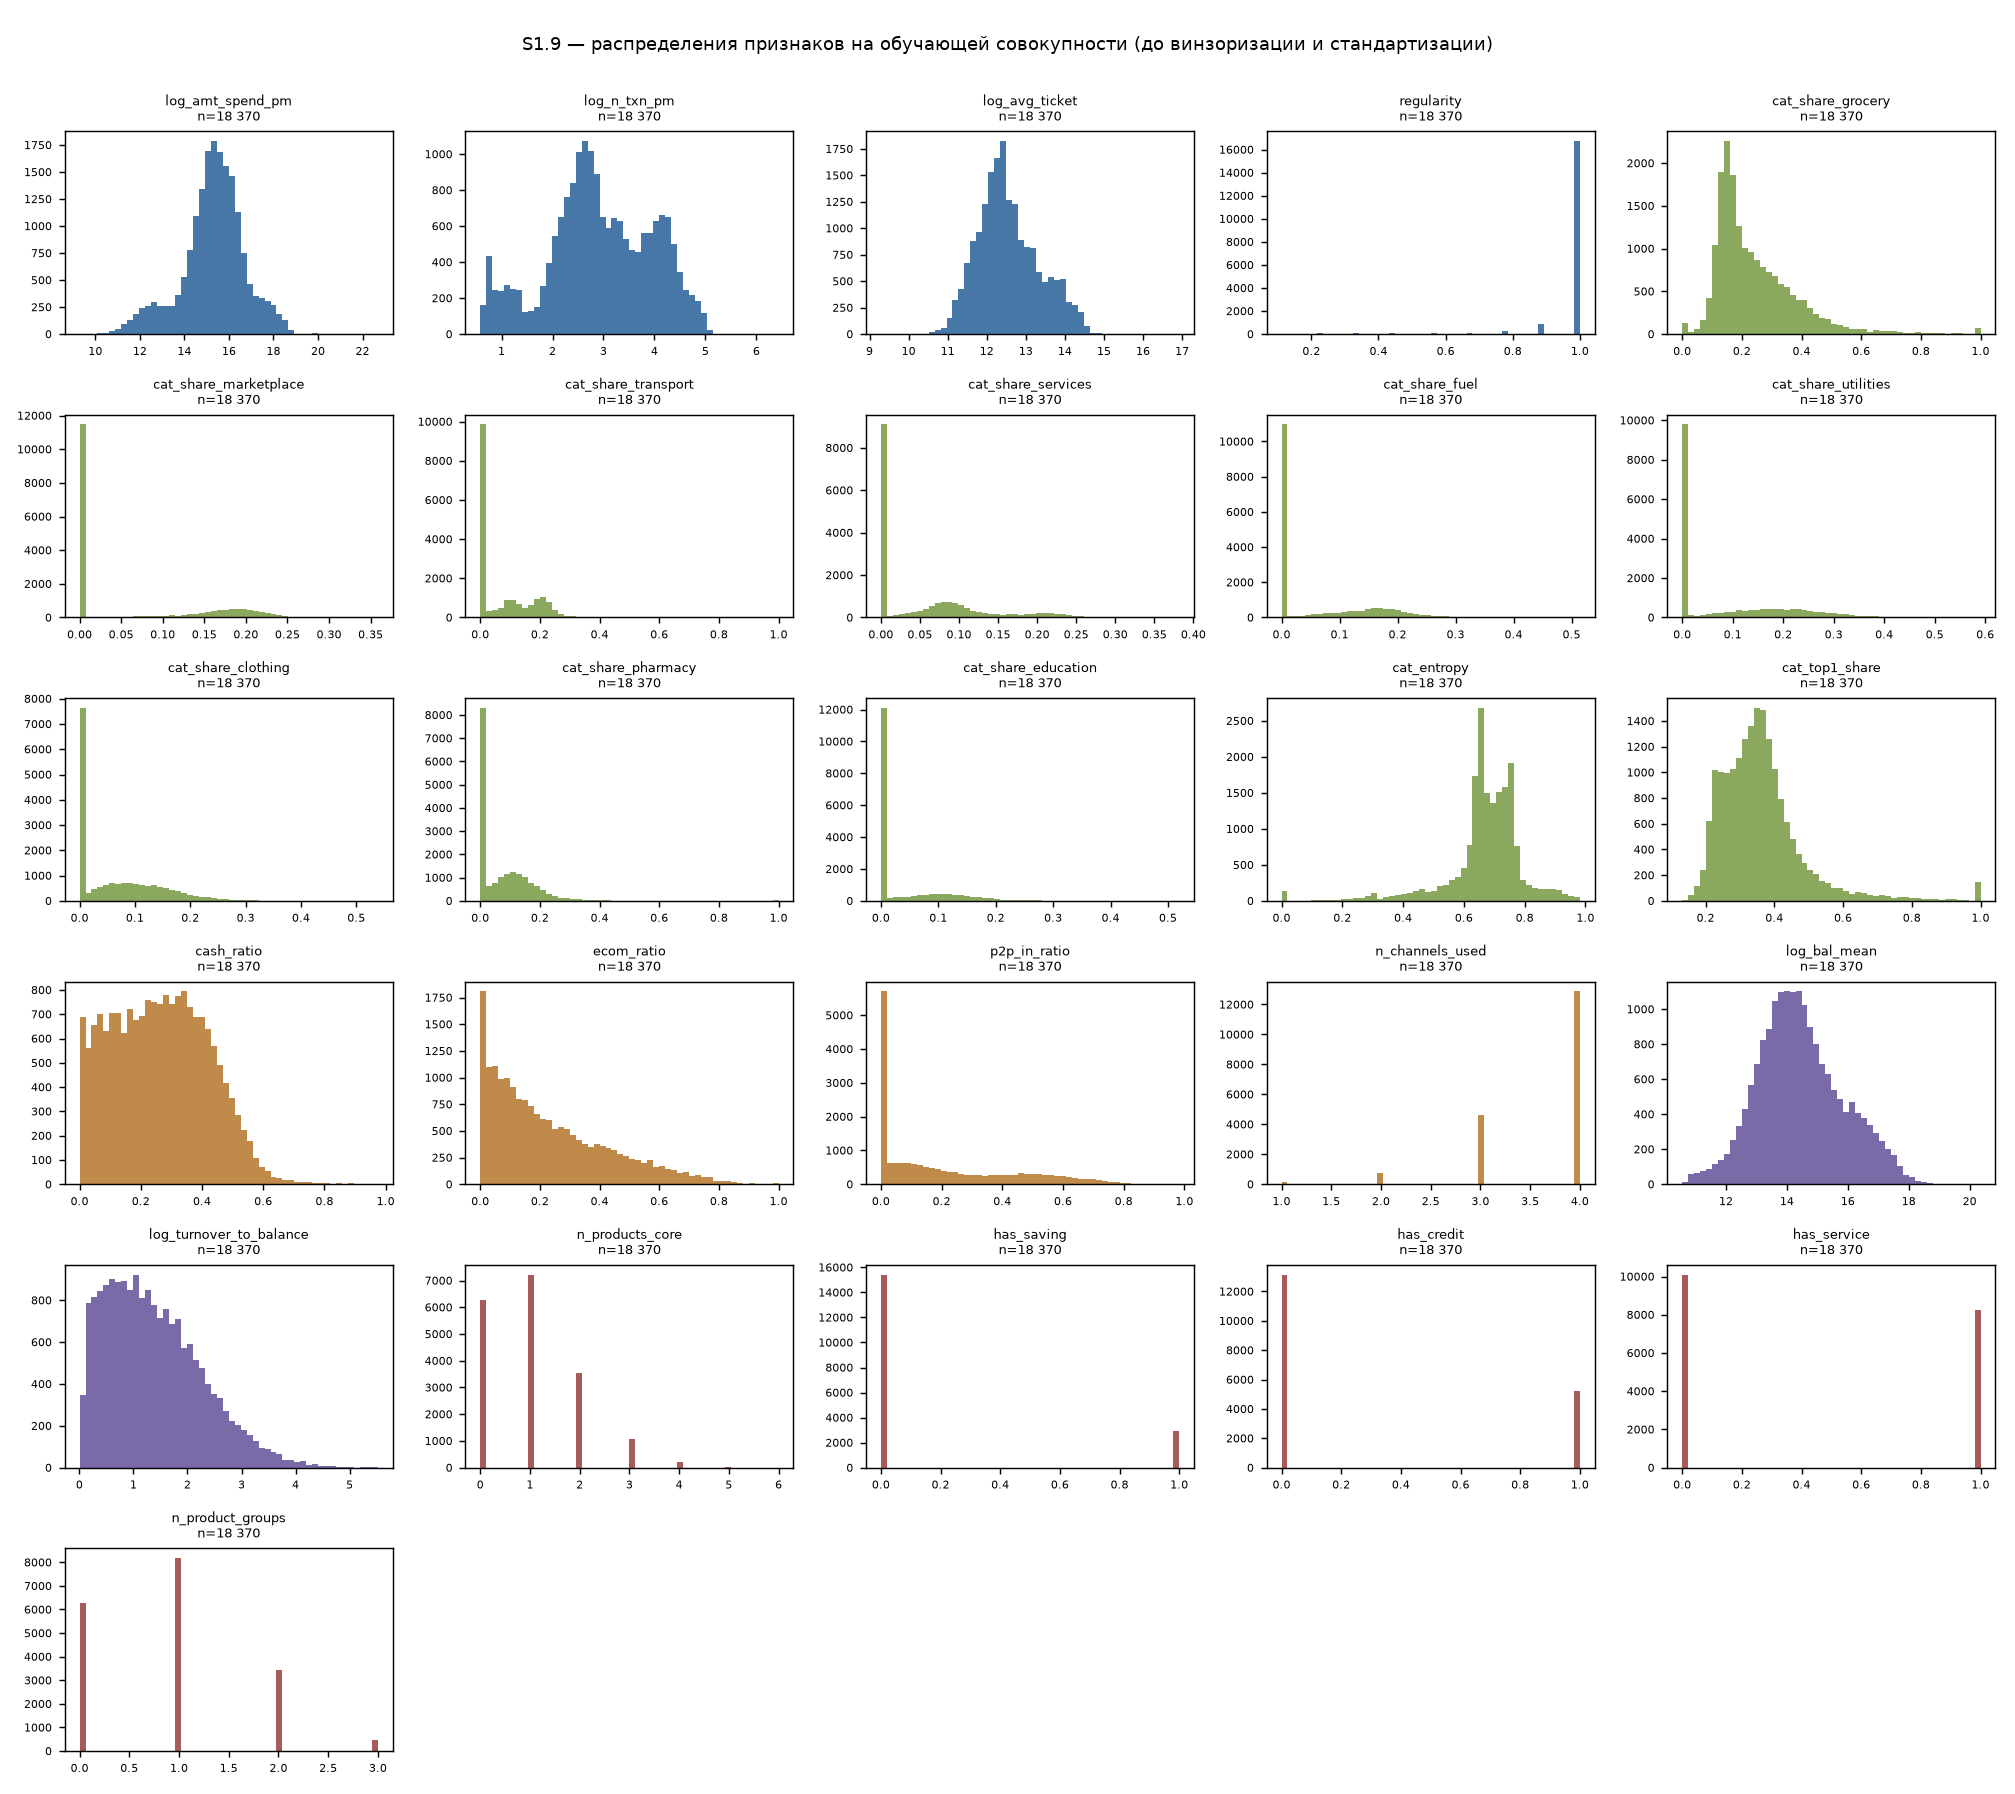

In [20]:
img("features/feature_distributions.png", width=900)

## Разбиение train / holdout

In [21]:
split = pd.read_parquet(DATA / "split_clients.parquet")
display(split["split"].value_counts().to_frame("клиентов"))
bal = art("features/train_holdout_balance.csv")
print("признаков с различием train/holdout:", (~bal["passed"].astype(bool)).sum(), "из", len(bal),
      "| максимальный η²:", bal["eta2"].max())

,клиентов
split,
train,14696
holdout,3674


признаков с различием train/holdout: 0 из 26 | максимальный η²: 8.6e-05


## Проверка на утечки

In [22]:
forbidden = ["rev", "revenue", "tariff", "crm", "segment", "rfm", "tenure", "signup", "customer_id"]
model_cols = pd.read_parquet(DATA / "features_model.parquet").columns.drop("customer_id")
hits = [c for c in model_cols if any(f in c.lower() for f in forbidden)]
print("запрещённых колонок среди признаков модели:", hits or "нет")

val = pd.read_parquet(DATA / "validators.parquet")
print("валидаторы (деньги) лежат в отдельном файле:", [c for c in val.columns if c.startswith("rev_v")][:3], "…")

запрещённых колонок среди признаков модели: нет


валидаторы (деньги) лежат в отдельном файле: ['rev_v_net', 'rev_v_interchange', 'rev_v_float'] …


In [23]:
art("features/column_leak_check.csv")

,проверка,что получилось,значение,вердикт
0,файл data/feature_store.parquet существует,нет; feature store физически называется features_wide.parquet,False,имя из DoD не существует как файл
1,колонок в features_wide.parquet,всего / признаков модели,37 / 26,справочно
2,колонок в validators.parquet,всего,16,справочно
3,следы денег банка среди колонок features_wide,не найдено ни одной,0,pass
4,колонки доходности в validators,"rev_v_net, rev_v_interchange, rev_v_float, rev_v_transfer_fee, rev_v_atm_cost, rev_v_m...",12,справочно: здесь они и должны быть
5,запретный класс «чужие сегменты» среди признаков модели,не найдено,0,pass
6,запретный класс «стаж и длина истории» среди признаков модели,не найдено,0,pass
7,запретный класс «тарифные опции (D-037)» среди признаков модели,не найдено,0,pass
8,пересечение колонок features_wide и validators,customer_id,1,pass: только ключ
9,md5 совпадает с манифестом: data/features_wide.parquet,совпадает,9bf28c56f5fe6a2cecd16d39aa13eb86,pass


In [24]:
lr = art("features/leakage_recheck.csv")
rechk = lr[lr["раздел"] == "пересчёт на train"]
print("решений пересчитано на train:", len(rechk), "| изменилось:", (rechk["решение изменилось"].astype(str) == "True").sum())

решений пересчитано на train: 28 | изменилось: 0


## Гейт этапа 1

In [25]:
gate = (ART / "stage1_gate.md").read_text(encoding="utf-8")
table = gate.split("## Сводная таблица")[1].split("---")[0]
display(Markdown(table))



| № | пункт | вердикт | ключевое число |
|

# Этап 2. Модель
## Корреляционный анализ

In [26]:
train_ids = set(split.loc[split.split == "train", "customer_id"])
train26 = fw[fw.customer_id.isin(train_ids)][feat26]
rho = train26.corr(method="spearman")

pairs = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack().dropna()
print("пар признаков всего:", len(pairs), "| медиана |rho|:", round(pairs.abs().median(), 4))
pairs[pairs.abs() > 0.85].round(4).to_frame("rho Спирмена")

пар признаков всего: 325 | медиана |rho|: 0.2125


,,rho Спирмена
cat_entropy,cat_top1_share,-0.8635
n_products_core,n_product_groups,0.9667


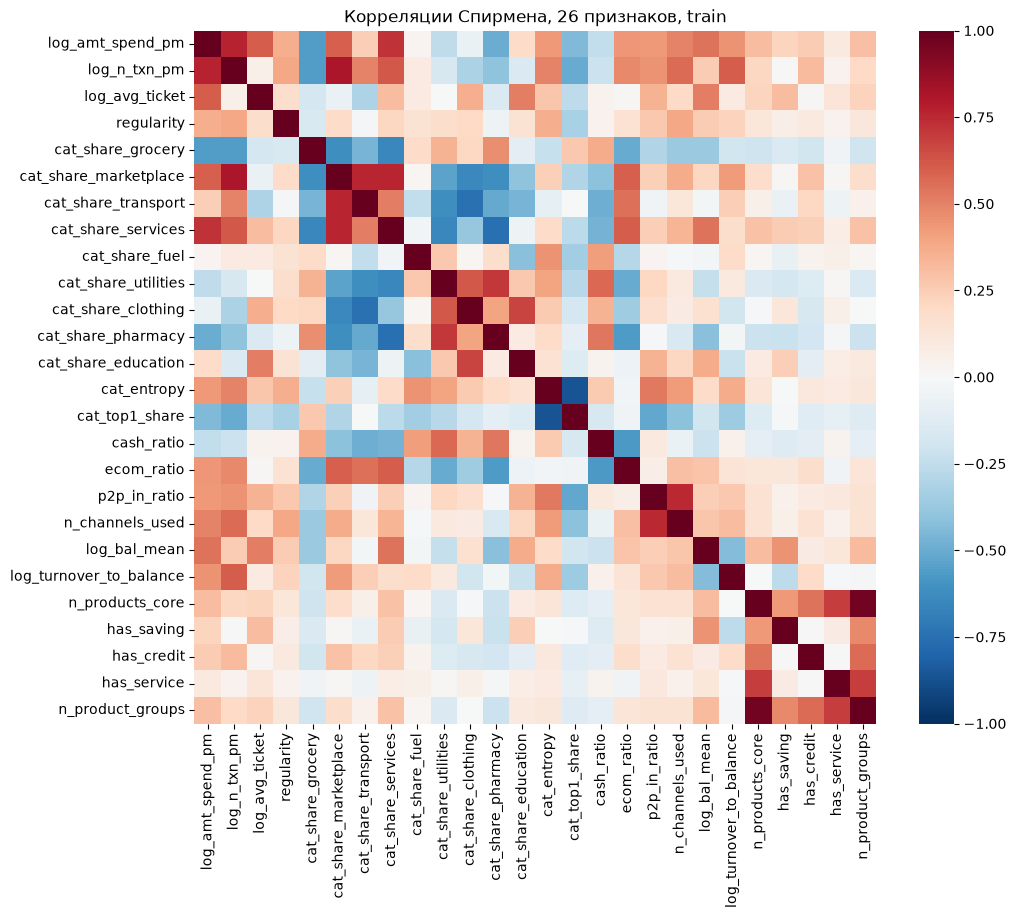

In [27]:
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(rho, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True)
ax.set_title("Корреляции Спирмена, 26 признаков, train")
plt.show()

## Удалённые признаки

In [28]:
art("features/dropped_features.csv")[["признак", "решение", "почему"]]

,признак,решение,почему
0,cat_entropy,убран,дубликат cat_top1_share (rho=-0.8635); приоритет: интерпретируемость 2 против 1 у оста...
1,cat_top1_share,оставлен,доля любимой категории — говорится одной фразой
2,n_product_groups,убран,дубликат n_products_core (rho=0.9667); приоритет: интерпретируемость 2 против 1 у оста...
3,n_products_core,оставлен,сколько продуктов у клиента — метрика кросс-сейла
4,regularity,убран,"вырожденность: доля пар клиентов, которых признак вообще различает = 0.1664, доля мода..."
5,n_channels_used,убран,"вырожденность: доля пар клиентов, которых признак вообще различает = 0.4449, доля мода..."
6,log_avg_ticket,убран,"избыточность (правило V2): VIF = 92.57 при пороге 10.0, R² на остальные признаки 0.989..."
7,log_turnover_to_balance,убран,"избыточность (правило V2): VIF = 17.39 при пороге 10.0, R² на остальные признаки 0.942..."


## Мультиколлинеарность (VIF)

In [29]:
vif = art("features/vif.csv")
vif[vif["набор"] == "финальный (20)"].sort_values("VIF", ascending=False)[["признак", "блок", "VIF", "вердикт"]]

,признак,блок,VIF,вердикт
113,cat_share_marketplace,B структура трат,11.5325,разобрать
114,log_n_txn_pm,A интенсивность,11.0074,разобрать
115,n_products_core,E глубина отношений,9.0681,ок
116,log_amt_spend_pm,A интенсивность,7.8236,ок
117,cat_share_services,B структура трат,5.4404,ок
118,cat_share_transport,B структура трат,5.0609,ок
119,has_service,E глубина отношений,4.4845,ок
120,cat_share_utilities,B структура трат,4.3008,ок
121,cat_share_education,B структура трат,3.8808,ок
122,has_credit,E глубина отношений,3.6823,ок


## PCA

In [30]:
fm = pd.read_parquet(DATA / "features_model.parquet")
FEATURES = [c for c in fm.columns if c != "customer_id"]
print("признаков в модели:", len(FEATURES))
art("model/pca_variance.csv").head(6)

признаков в модели: 20


,компонента,собственное_значение,доля_дисперсии,накопленная_доля
0,PC1,5.976360,0.298798,0.298798
1,PC2,3.412599,0.170618,0.469416
2,PC3,2.244108,0.112198,0.581614
3,PC4,1.723164,0.086152,0.667766
4,PC5,1.219949,0.060993,0.728759
5,PC6,0.928541,0.046424,0.775183


## Препроцессинг

In [31]:
pc = art("model/preprocess_comparison.csv")
pc[pc["k"] == 6][["вариант", "К0_пройден", "К0_макс_доля_на_границе", "макс_NMI_разметка_флаг",
                  "К2_ARI_min", "К3_доля_PC1", "размеры_кластеров"]]

,вариант,К0_пройден,К0_макс_доля_на_границе,макс_NMI_разметка_флаг,К2_ARI_min,К3_доля_PC1,размеры_кластеров
2,P1,True,0.000000,0.079889,0.997089,0.301661,1580 / 1805 / 1879 / 2571 / 3361 / 3500
5,P2,True,0.000000,0.073199,0.997602,0.336115,1603 / 1817 / 1848 / 2566 / 3371 / 3491
8,P3,False,0.839344,0.501648,0.552359,0.281584,1551 / 1722 / 2194 / 2706 / 3260 / 3263


## Пайплайн, обученный на train

In [32]:
model = joblib.load(DATA / "model.joblib")
pipe, kmeans = model["pipeline"], model["kmeans"]
assert model["features"] == FEATURES
display(pipe)

d = fm.merge(split, on="customer_id")
X_tr = d.loc[d.split == "train", FEATURES].to_numpy()
X_ho = d.loc[d.split == "holdout", FEATURES].to_numpy()
print("границы обрезки = перцентили train:",
      np.allclose(pipe.named_steps["winsor"].lo_, np.quantile(X_tr, 0.01, axis=0)))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('winsor', ...), ('log1p', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,q_low,0.01
,q_high,0.99
Name,Type,Value
hi_,"ndarray[float64](20,)","[18.42, 4.89, 0.78,..., 1. , 1. , 1. ]"
lo_,"ndarray[float64](20,)","[11.39, 0.7 , 0.05,..., 0. , 0. , 0. ]"


границы обрезки = перцентили train: True


In [33]:
Z_tr, Z_ho = pipe.transform(X_tr), pipe.transform(X_ho)
scaled = ~np.isin(FEATURES, ["has_saving", "has_credit", "has_service"])
pd.DataFrame({"train: макс |среднее|": [np.abs(Z_tr.mean(0)).max()],
              "train: σ (без флагов), мин–макс": [f"{Z_tr[:, scaled].std(0).min():.4f}–{Z_tr[:, scaled].std(0).max():.4f}"],
              "holdout: макс |среднее|": [np.abs(Z_ho.mean(0)).max()]}).T.rename(columns={0: "значение"})

,значение
train: макс |среднее|,0.0
"train: σ (без флагов), мин–макс",1.0000–1.0000
holdout: макс |среднее|,0.025273


## Кластерная тенденция

In [34]:
art("model/tendency_summary.csv")

,проверка,реальные,нулевая_модель,интервал_нуля_99,порог_выраженных_групп,вердикт
0,"Хопкинс, 20 признаков, окно маргиналов",0.727085,0.500486,[0.495058; 0.504708],0.75,континуум
1,"Хопкинс, 17 непрерывных (без флагов)",0.730284,0.500529,[0.495769; 0.504091],0.75,континуум
2,"VAT, контраст диагонали (полоса n/4)",0.085414,0.017682,положительный контроль 0.367048,0.192365,ближе к нулевой модели
3,"расстояние до k-го соседа, k = 1/10/50","[1.1241, 1.5895, 1.9745]","[2.5213, 3.0868, 3.5056]",вне интервала у 3 из 3 k,—,отличается от нулевой
4,"острова UMAP, оценённые силуэтом в рабочем пространстве Z",0.173534,0.04193,KMeans k=9 в Z даёт 0.226272,—,острова UMAP в Z не подтверждаются


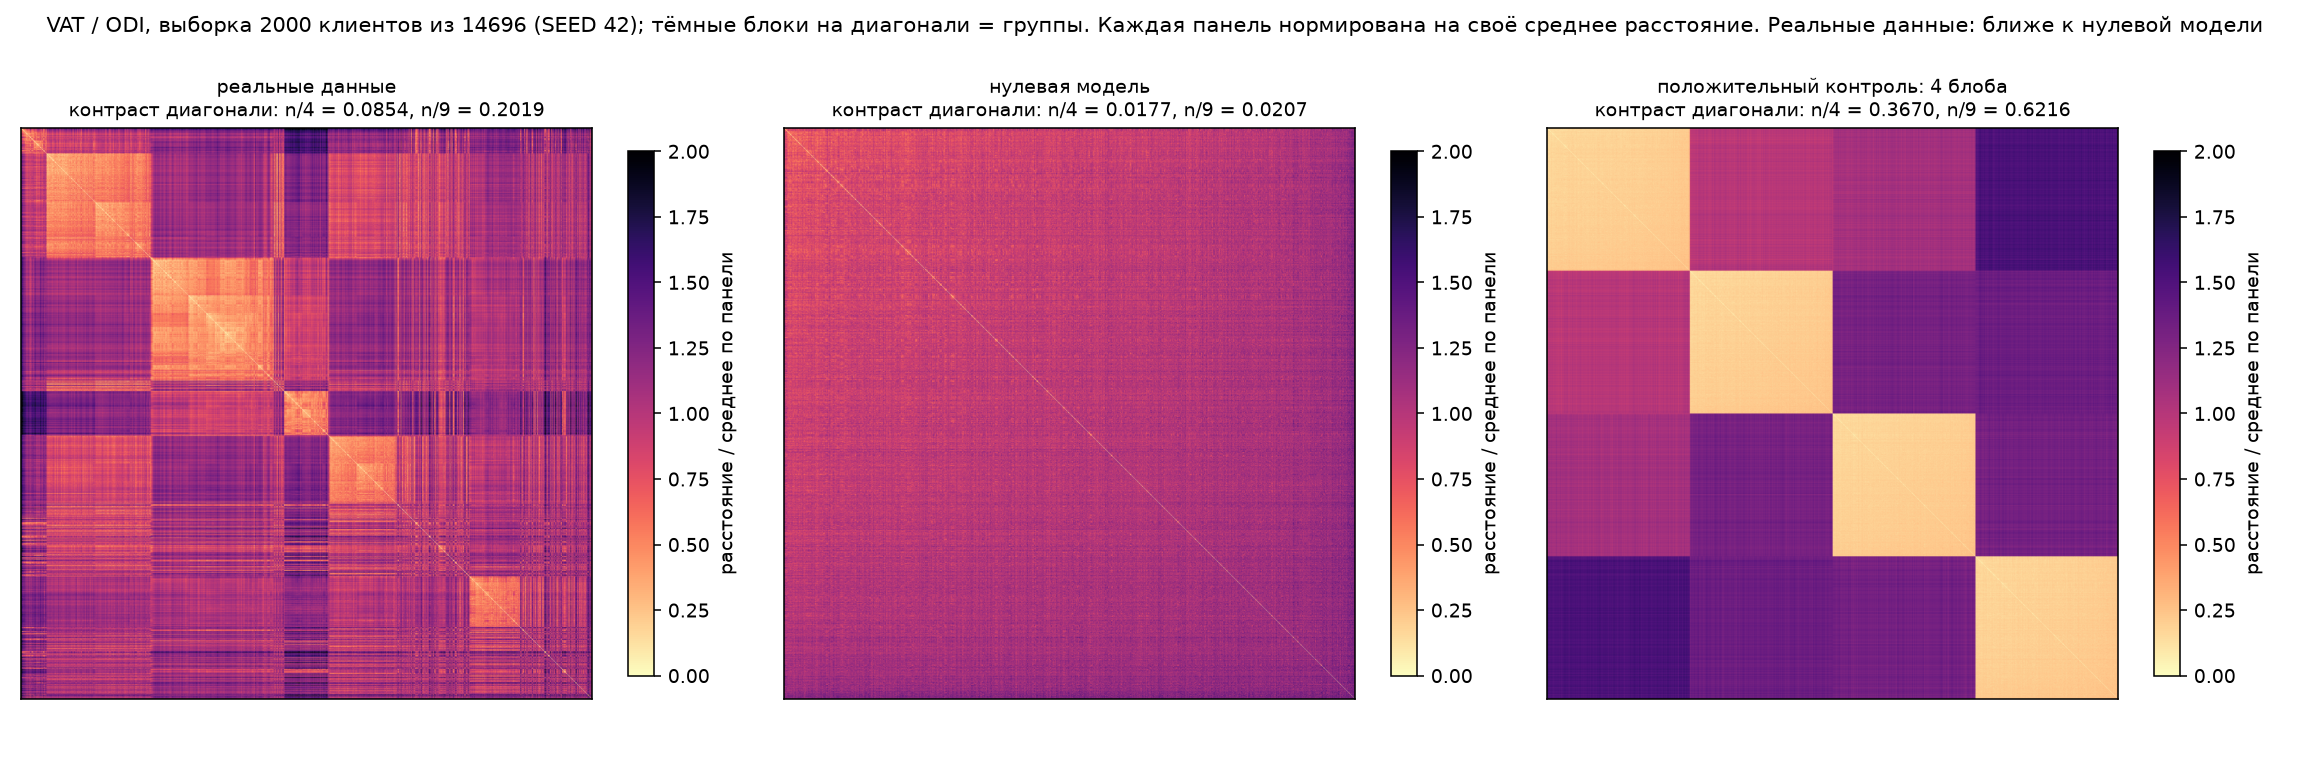

In [35]:
img("model/vat_matrix.png", width=700)

## Число кластеров: локоть, силуэт, CH, DB

In [36]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

rows = []
for k in range(2, 13):
    lab = KMeans(n_clusters=k, n_init=25, random_state=SEED).fit(Z_tr)
    rows.append({"k": k, "инерция": lab.inertia_,
                 "силуэт": silhouette_score(Z_tr, lab.labels_),
                 "calinski_harabasz": calinski_harabasz_score(Z_tr, lab.labels_),
                 "davies_bouldin": davies_bouldin_score(Z_tr, lab.labels_)})
grid = pd.DataFrame(rows).set_index("k")
grid.round(4)

,инерция,силуэт,calinski_harabasz,davies_bouldin
k,,,,
2,186359.6185,0.2761,5770.3488,1.4254
3,152150.7699,0.2761,5185.3739,1.5712
4,131363.3485,0.3012,4778.6524,1.3072
5,113009.2507,0.3046,4762.2890,1.2859
6,95054.4957,0.3169,5084.1144,1.2436
7,91382.4103,0.3126,4505.0868,1.4160
8,88451.8802,0.2609,4058.6872,1.5567
9,86090.9276,0.2555,3698.8419,1.6422
10,83822.9504,0.2072,3420.7412,1.8243


In [37]:
saved = art("model/k_metrics.csv").set_index("k")
diff = (grid["силуэт"] - saved["силуэт_среднее"]).abs().max()
print("максимальное расхождение силуэта с артефактом:", f"{diff:.2e}")

from kneed import KneeLocator
knee = KneeLocator(grid.index, grid["инерция"], curve="convex", direction="decreasing").knee
print("локоть (kneed):", knee, "| максимум силуэта:", grid["силуэт"].idxmax(),
      "| минимум Davies–Bouldin:", grid["davies_bouldin"].idxmin(), "| максимум CH:", grid["calinski_harabasz"].idxmax())

максимальное расхождение силуэта с артефактом: 4.94e-07
локоть (kneed): 6 | максимум силуэта: 6 | минимум Davies–Bouldin: 6 | максимум CH: 2


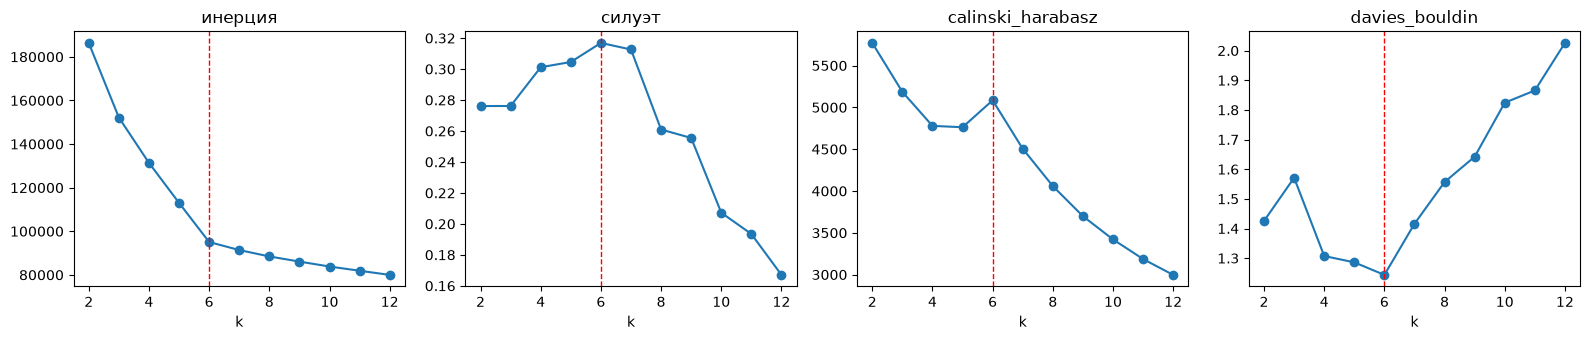

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, grid.columns):
    ax.plot(grid.index, grid[col], marker="o")
    ax.axvline(6, color="red", ls="--", lw=1)
    ax.set(title=col, xlabel="k")
plt.tight_layout(); plt.show()

## Gap statistic и устойчивость

In [39]:
gap = art("model/gap_statistic.csv")
display(gap.pivot(index="k", columns="эталон", values="gap").round(4))
print("правило Тибширани выполнено хотя бы раз:", gap["правило_Тибширани_выполнено"].any())
saved[["устойчивость_ARI_медиана", "устойчивость_ARI_min", "prediction_strength_среднее", "мин_кластер_n", "мин_кластер_доля"]]

эталон,box,pca,shuffle
k,,,
2,0.5589,1.4555,0.2773
3,0.7156,1.5842,0.4425
4,0.8273,1.6804,0.5594
5,0.9529,1.8045,0.6853
6,1.1030,1.9526,0.8366
7,1.1244,1.9713,0.8556
8,1.1387,1.9833,0.8695
9,1.1546,1.9948,0.8793
10,1.1702,2.0063,0.8909


правило Тибширани выполнено хотя бы раз: False


,устойчивость_ARI_медиана,устойчивость_ARI_min,prediction_strength_среднее,мин_кластер_n,мин_кластер_доля
k,,,,,
2,0.997948,0.991806,0.996860,5337,0.363160
3,0.997198,0.994797,0.992047,4501,0.306274
4,0.996813,0.994405,0.982801,1650,0.112275
5,0.997553,0.611908,0.660755,1581,0.107580
6,0.998608,0.997394,0.994262,1578,0.107376
7,0.996334,0.895981,0.857326,648,0.044094
8,0.994232,0.795166,0.788045,685,0.046611
9,0.824001,0.818704,0.687744,676,0.045999
10,0.928970,0.790703,0.628474,618,0.042052


## DBSCAN

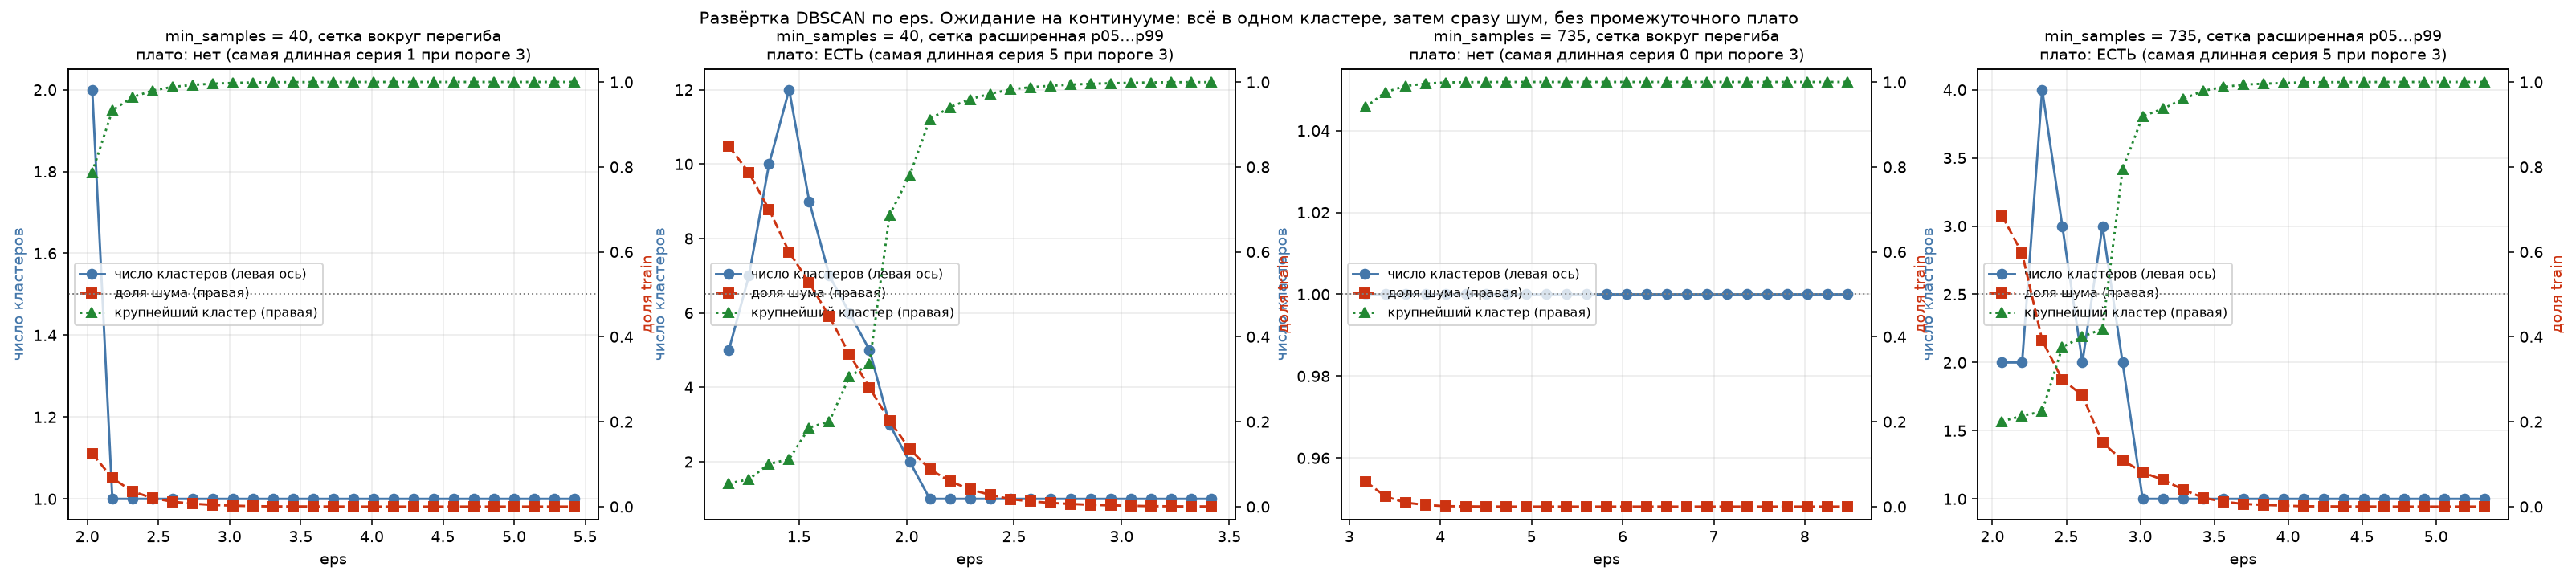

In [40]:
img("model/dbscan_curves.png", width=900)

In [41]:
dbk = art("model/dbscan_vs_kmeans_ari.csv")
dbk.iloc[[0]][["конфигурация", "кластеров_DBSCAN", "доля_шума", "нешумовых_точек", "ARI_с_KMeans6_на_нешумовых", "AMI_с_KMeans6_на_нешумовых"]]

,конфигурация,кластеров_DBSCAN,доля_шума,нешумовых_точек,ARI_с_KMeans6_на_нешумовых,AMI_с_KMeans6_на_нешумовых
0,"eps=1.640799, min_samples=40",7.0,0.447333,8122.0,0.994196,0.987354


## Выбор k

In [42]:
kd = art("model/k_decision_table.csv").set_index("k")
kd[["силуэт", "davies_bouldin", "устойчивость_ARI_min", "prediction_strength", "мин_кластер_проекция_на_20000",
    "П3_R10_пройден", "победил_при_пороге_3проц", "победил_при_пороге_5проц", "победил_при_пороге_10проц",
    "ARI_с_k_тилями_оборота", "eta2_log_оборот", "eta2_стаж"]]

,силуэт,davies_bouldin,устойчивость_ARI_min,prediction_strength,мин_кластер_проекция_на_20000,П3_R10_пройден,победил_при_пороге_3проц,победил_при_пороге_5проц,победил_при_пороге_10проц,ARI_с_k_тилями_оборота,eta2_log_оборот,eta2_стаж
k,,,,,,,,,,,,
2,0.276105,1.425442,0.991806,0.996860,7263,True,False,False,False,0.159056,0.262399,0.000014
3,0.276138,1.571167,0.994797,0.992047,6125,True,False,False,False,0.305658,0.515794,0.000075
4,0.301181,1.307244,0.994405,0.982801,2246,True,False,False,False,0.137331,0.605280,0.000147
5,0.304555,1.285898,0.611908,0.660755,2152,True,False,False,False,0.200318,0.671684,0.000308
6,0.316876,1.243555,0.997394,0.994262,2148,True,True,True,True,0.272884,0.816169,0.001346
7,0.312636,1.415969,0.895981,0.857326,882,False,False,False,False,0.255559,0.814309,0.001344
8,0.260944,1.556727,0.795166,0.788045,932,False,False,False,False,0.257858,0.814711,0.001874
9,0.255503,1.642188,0.818704,0.687744,920,False,False,False,False,0.240861,0.816424,0.002013
10,0.207212,1.824285,0.790703,0.628474,841,False,False,False,False,0.204124,0.820381,0.002210


## Эффект китов

In [43]:
ds = art("model/defence_sheet.csv")
ds[ds["утверждение"].str.contains("кит|lift", case=False)][["блок", "утверждение", "значение"]]

,блок,утверждение,значение
9,2.2 препроцессинг,k=4: ARI при удалении китов против контроля из 74 случайных не-китов,0.664717 против 0.664837
10,2.2 препроцессинг,k=5: ARI при удалении китов против контроля из 74 случайных не-китов,0.612676 против 0.999451
11,2.2 препроцессинг,k=6: ARI при удалении китов против контроля из 74 случайных не-китов,0.998841 против 0.999686
31,2.5 DBSCAN,lift китов в шуме — киты НЕ выбросы,0.6646
50,2.6 киты,lift китов в их кластере при k=6,6.554277
51,2.6 киты,доля всех китов в этом кластере,0.810811
52,2.6 киты,lift китов при k=5 — почему 5 хуже,2.482917
54,2.6 продукты,"максимум по lift среди отдельных продуктов: prod_deposit, кластер 4 — доля владельцев",0.550623
56,2.6 продукты,— lift,3.42734
58,2.6 продукты,"максимум по доле среди групповых флагов: grp_service, кластер 2 (база 0.523476, lift 1...",0.785479


## Финальная модель

In [44]:
labels = pd.read_parquet(DATA / "cluster_labels.parquet")
d["pred"] = kmeans.predict(pipe.transform(d[FEATURES].to_numpy()))
chk = d.merge(labels[["customer_id", "cluster"]], on="customer_id")
print("размечено клиентов:", len(chk), "| расхождений с cluster_labels.parquet:", int((chk.pred != chk.cluster).sum()))

размечено клиентов: 18370 | расхождений с cluster_labels.parquet: 0


## Размеры кластеров

In [45]:
prof = art("model/cluster_profiles.csv")
TYPE = prof.drop_duplicates("cluster").set_index("cluster")["тип"]

sizes = d.groupby("pred").size().rename("клиентов").to_frame()
sizes.insert(0, "тип", TYPE)
sizes["доля_базы_20000"] = sizes["клиентов"] / 20000
sizes["R10: ≥ 1000"] = sizes["клиентов"] >= 1000
sizes

,тип,клиентов,доля_базы_20000,R10: ≥ 1000
pred,,,,
0,Офлайн-быт за наличные,4382,0.21910,True
1,Цифровой городской,4191,0.20955,True
2,Тяжёлый универсал (киты),2290,0.11450,True
3,Семейные платежи,3207,0.16035,True
4,Сберегатель,2328,0.11640,True
5,Спящий минимум,1972,0.09860,True


## Профили кластеров

макс. расхождение с cluster_profiles.csv: 4.92e-07


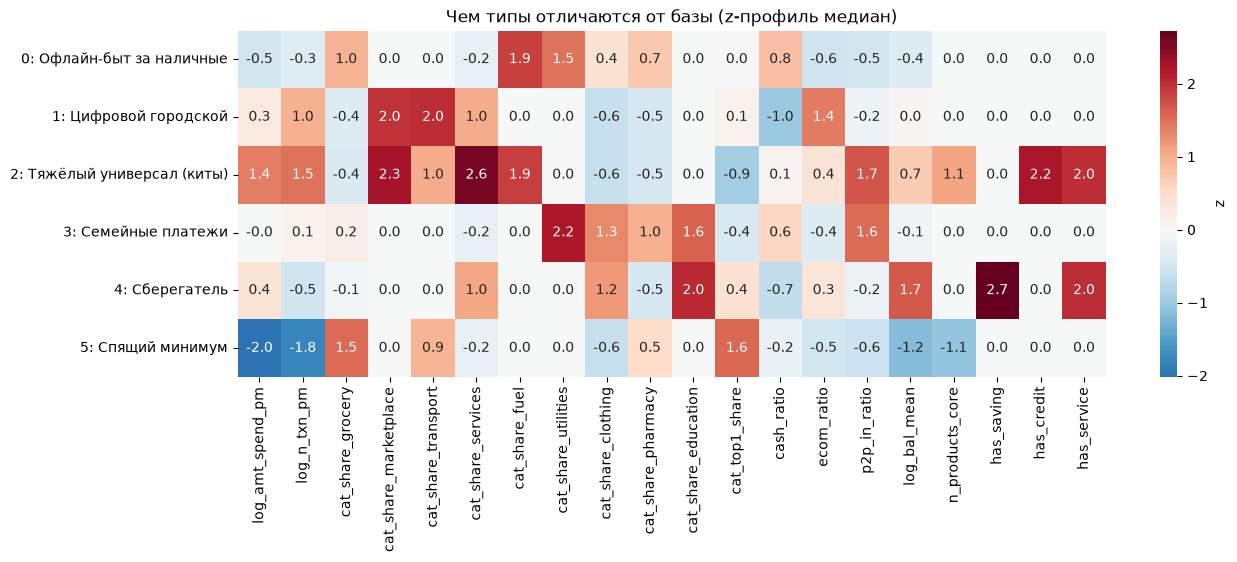

In [46]:
base_med, base_std = d[FEATURES].median(), d[FEATURES].std()
z = (d.groupby("pred")[FEATURES].median() - base_med) / base_std
z.index = [f"{c}: {TYPE[c]}" for c in z.index]

saved_z = prof.pivot(index="cluster", columns="признак", values="z_профиль")[FEATURES]
print("макс. расхождение с cluster_profiles.csv:", f"{np.abs(z.to_numpy() - saved_z.to_numpy()).max():.2e}")

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(z, cmap="RdBu_r", center=0, annot=True, fmt=".1f", ax=ax, cbar_kws={"label": "z"})
ax.set_title("Чем типы отличаются от базы (z-профиль медиан)")
plt.show()

## Важность признаков

In [47]:
art("model/cluster_effects.csv")[["признак", "ось", "eta2", "p_adj_bh"]].head(10)

,признак,ось,eta2,p_adj_bh
0,cat_share_marketplace,B структура трат,0.905886,0.0
1,cat_share_services,B структура трат,0.877122,0.0
2,cat_share_fuel,B структура трат,0.852525,0.0
3,cat_share_education,B структура трат,0.844860,0.0
4,cat_share_utilities,B структура трат,0.840652,0.0
5,log_n_txn_pm,A интенсивность,0.826458,0.0
6,cat_share_transport,B структура трат,0.785579,0.0
7,cat_share_clothing,B структура трат,0.773902,0.0
8,log_amt_spend_pm,A интенсивность,0.696420,0.0
9,cat_share_pharmacy,B структура трат,0.664914,0.0


## Профили в исходных единицах

In [48]:
rm = art("money/cluster_readable_medians.csv")
rm.pivot(index="величина", columns="тип", values="медиана_кластера").round(2)

тип,Офлайн-быт за наличные,Сберегатель,Семейные платежи,Спящий минимум,Тяжёлый универсал (киты),Цифровой городской
величина,,,,,,
"операций в месяц, шт",11.34,8.96,18.78,1.73,78.10,46.42
"расход в месяц, сум",2318155.93,8020472.36,4761497.56,261628.59,35895445.25,7176238.09
"средний остаток, сум",972083.49,17246347.54,1388258.00,312859.91,4418795.80,1703162.56


## Визуализация кластеров (PCA)

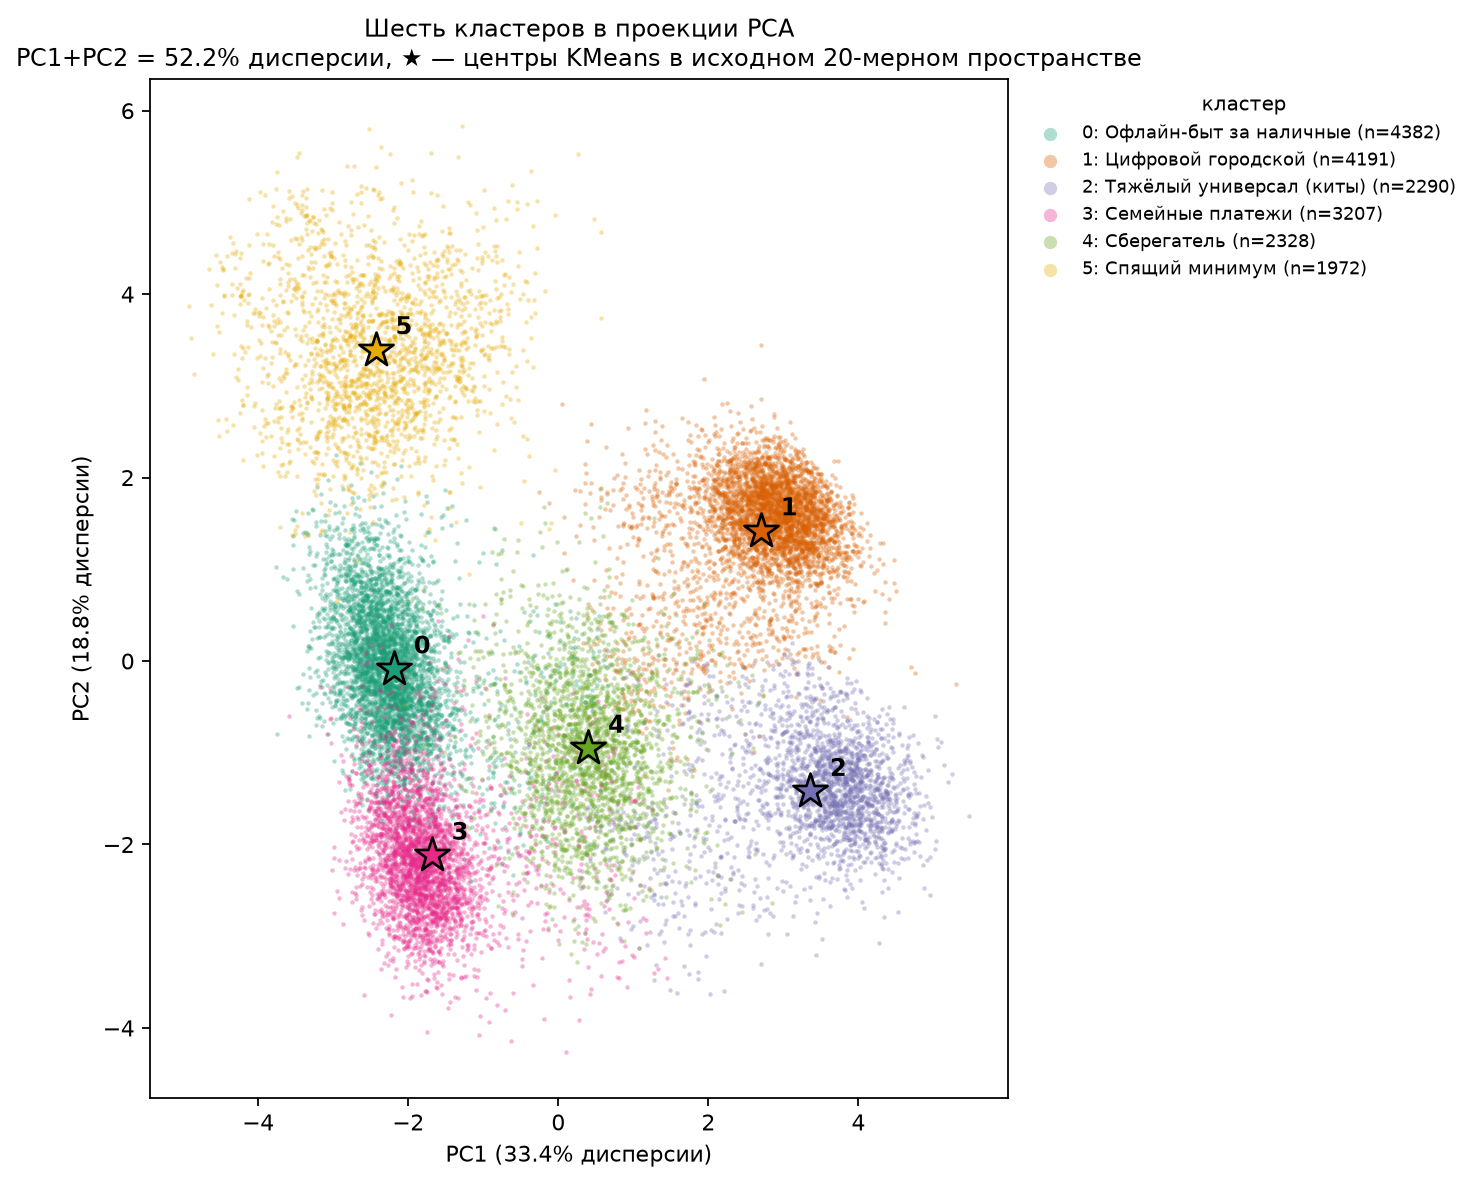

In [49]:
img("model/pca_clusters.png", width=750)

## Внешняя валидация

In [50]:
art("model/external_validation.csv")[["валидатор", "метрика", "значение", "доля"]]

,валидатор,метрика,значение,доля
0,а_продукты_в_V,клиентов с ≥1 подключением в V,3.534000e+03,0.192379
1,а_продукты_в_V,подключений всего в V,3.950000e+03,NaN
2,а_продукты_в_V,χ² (наличие подключения × кластер),2.949684e+02,NaN
3,а_продукты_в_V,χ² p-value,1.208700e-61,NaN
4,а_продукты_в_V,Cramér's V (наличие подключения × кластер),1.267160e-01,NaN
5,а_продукты_в_V,Kruskal-Wallis η² (число подключений × кластер),1.641500e-02,NaN
6,а_продукты_в_V,Kruskal-Wallis p-value,4.122930e-64,NaN
7,б_поведение_в_V,клиентов с активностью в V среди размеченных,1.827700e+04,0.994937
8,б_поведение_в_V,"Спирмен(η²_W, η²_V) по 16 признакам",9.647060e-01,NaN
9,б_поведение_в_V,"медиана Спирмена(z-профиль W, z-профиль V) по кластерам",9.686100e-01,NaN


## Демография

In [51]:
art("model/demographic_significance.csv")[["переменная", "тест", "p", "эффект", "вердикт"]]

,переменная,тест,p,эффект,вердикт
0,gender,χ² + Cramér's V,0.167149,0.020616,различий нет
1,age_group,χ² + Cramér's V,0.568366,0.015777,различий нет
2,region,χ² + Cramér's V,0.846630,0.023073,различий нет
3,age (непрерывный),Kruskal-Wallis + η²,0.747205,-0.000126,различий нет


## Перенос на holdout

In [52]:
share = pd.crosstab(d["pred"].map(TYPE), d["split"], normalize="columns").round(4)
share["разница"] = (share["holdout"] - share["train"]).round(4)
share

split,holdout,train,разница
pred,,,
Офлайн-быт за наличные,0.2376,0.2388,-0.0012
Сберегатель,0.1309,0.1257,0.0052
Семейные платежи,0.1696,0.1758,-0.0062
Спящий минимум,0.1072,0.1074,-0.0002
Тяжёлый универсал (киты),0.1285,0.1237,0.0048
Цифровой городской,0.2262,0.2286,-0.0024


## Доходность по кластерам (окно V)

In [53]:
lab_val = labels[["customer_id", "cluster"]].merge(val[["customer_id", "rev_v_net", "rev_v_months"]], on="customer_id")
lab_val["тип"] = lab_val["cluster"].map(TYPE).fillna("не размечены (вне обучения)")
total = lab_val["rev_v_net"].sum()

money = lab_val.groupby("тип").agg(клиентов=("customer_id", "size"), доходность_V=("rev_v_net", "sum"))
money["доля_базы"] = money["клиентов"] / 20000
money["доля_доходности_V"] = money["доходность_V"] / total
money["медиана_в_мес_на_клиента"] = lab_val.groupby("тип").apply(lambda g: (g.rev_v_net / g.rev_v_months).median())
money.sort_values("доля_доходности_V", ascending=False).round(4)

,клиентов,доходность_V,доля_базы,доля_доходности_V,медиана_в_мес_на_клиента
тип,,,,,
Тяжёлый универсал (киты),2290,2459699692,0.1145,0.4038,273773.5000
Сберегатель,2328,1323026378,0.1164,0.2172,156508.3333
Цифровой городской,4191,1030021218,0.2096,0.1691,63094.0000
не размечены (вне обучения),1630,489467485,0.0815,0.0804,25050.8333
Семейные платежи,3207,465150426,0.1604,0.0764,35180.0000
Офлайн-быт за наличные,4382,293824264,0.2191,0.0482,16311.5000
Спящий минимум,1972,29939395,0.0986,0.0049,3297.0000


макс. расхождение долей доходности с cluster_money_v.csv: 8.33e-17


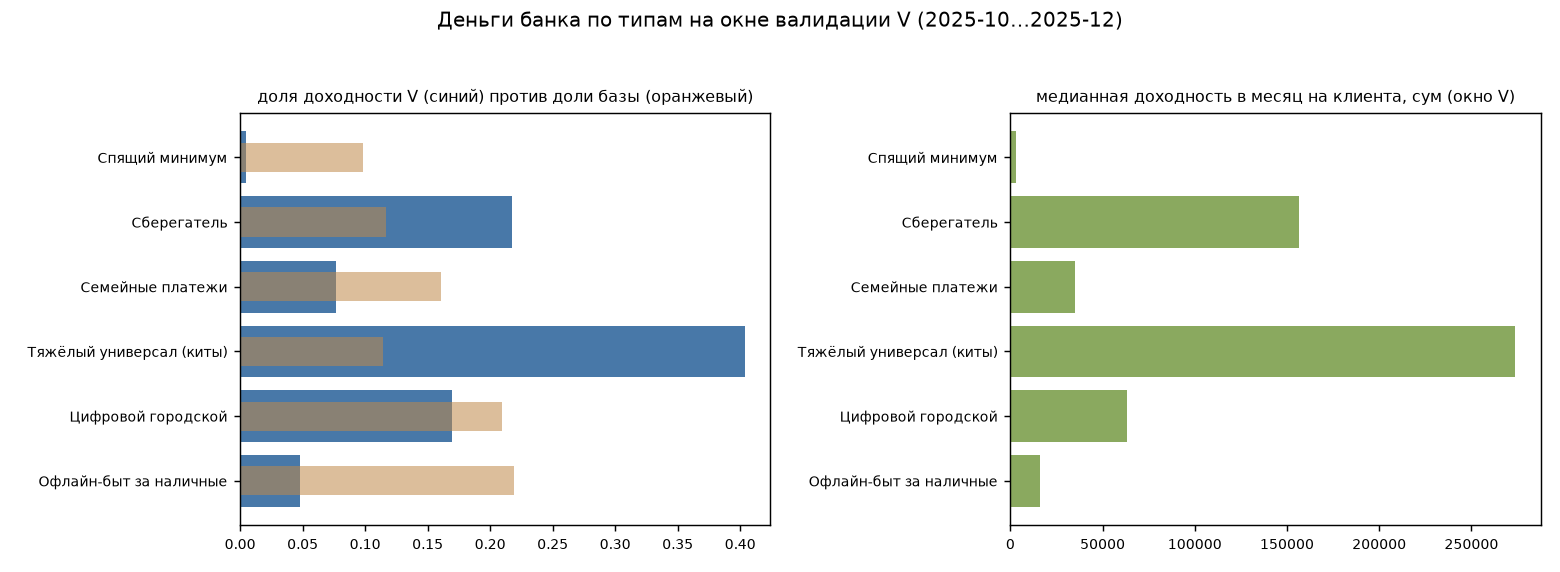

In [54]:
saved_m = art("money/cluster_money_v.csv").set_index("тип")["доля_доходности_V"]
common_types = money.index.intersection(saved_m.index)
print("макс. расхождение долей доходности с cluster_money_v.csv:",
      f"{(money.loc[common_types, 'доля_доходности_V'] - saved_m[common_types]).abs().max():.2e}")
img("money/cluster_money_v.png", width=750)

## Сравнение с квартилями оборота

In [55]:
kd.loc[[4, 6], ["ARI_с_k_тилями_оборота", "AMI_с_k_тилями_оборота", "eta2_log_оборот",
                "eta2_log_оборот_у_самих_тилей", "доля_от_потолка_тилей"]]

,ARI_с_k_тилями_оборота,AMI_с_k_тилями_оборота,eta2_log_оборот,eta2_log_оборот_у_самих_тилей,доля_от_потолка_тилей
k,,,,,
4,0.137331,0.221652,0.605280,0.777198,0.778797
6,0.272884,0.383035,0.816169,0.874342,0.933466


## Клиенты вне обучения

,причина,клиентов,доля_базы
0,холодный старт (история < 9 мес),1258,0.0629
1,"молчащие в окне (окно доступно, операций нет)",372,0.0186
2,ИТОГО вне обучения,1630,0.0815


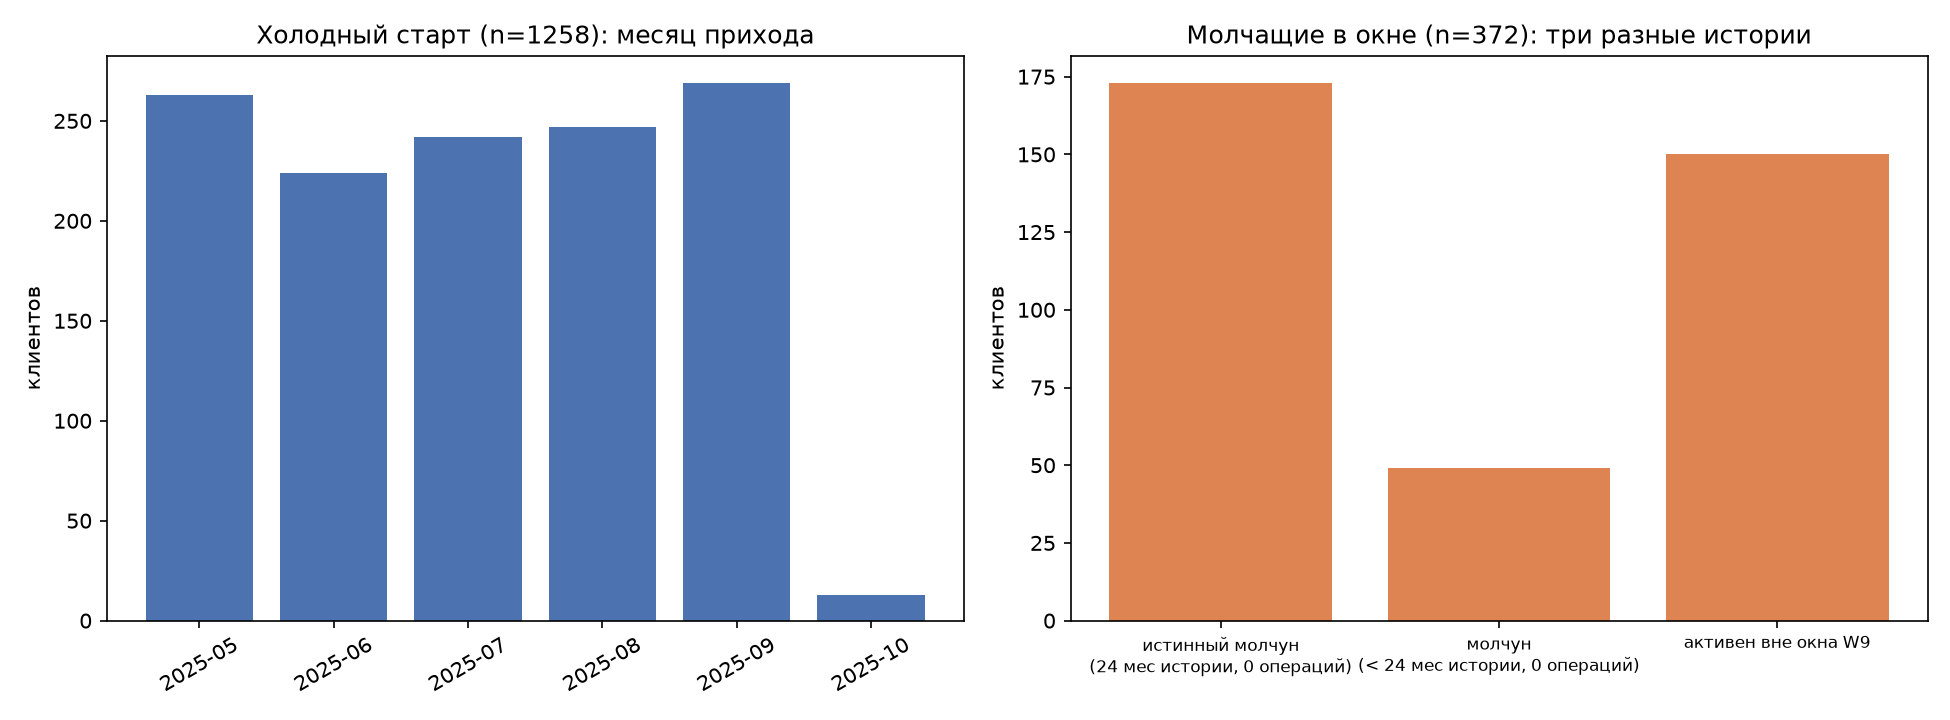

In [56]:
display(art("model/out_of_training_overview.csv"))
img("model/out_of_training_composition.png", width=750)

# Итог
## Типы клиентов

In [57]:
offers = {
    "Офлайн-быт за наличные": ("топливо и наличные выше базы, онлайн ниже", "кэшбэк АЗС и продукты; перевод вместо снятия"),
    "Цифровой городской": ("транспорт и маркетплейсы выше базы, наличные ниже", "кэшбэк маркетплейс + транспорт"),
    "Тяжёлый универсал (киты)": ("самый большой оборот и самая широкая корзина", "персональная работа, не тариф"),
    "Семейные платежи": ("ЖКУ, образование и входящие переводы выше базы", "автоплатёж ЖКУ + рассрочка на обучение"),
    "Сберегатель": ("самый высокий остаток, чаще есть депозит", "депозитная линейка, накопительный счёт"),
    "Спящий минимум": ("минимальные траты, почти одна категория", "активация, а не тариф"),
}
summary = money.loc[TYPE.values, ["клиентов", "доля_базы", "доля_доходности_V", "медиана_в_мес_на_клиента"]].round(4)
summary["чем отличается"] = [offers[t][0] for t in summary.index]
summary["предложение"] = [offers[t][1] for t in summary.index]
summary

,клиентов,доля_базы,доля_доходности_V,медиана_в_мес_на_клиента,чем отличается,предложение
тип,,,,,,
Офлайн-быт за наличные,4382,0.2191,0.0482,16311.5000,"топливо и наличные выше базы, онлайн ниже",кэшбэк АЗС и продукты; перевод вместо снятия
Цифровой городской,4191,0.2096,0.1691,63094.0000,"транспорт и маркетплейсы выше базы, наличные ниже",кэшбэк маркетплейс + транспорт
Тяжёлый универсал (киты),2290,0.1145,0.4038,273773.5000,самый большой оборот и самая широкая корзина,"персональная работа, не тариф"
Семейные платежи,3207,0.1604,0.0764,35180.0000,"ЖКУ, образование и входящие переводы выше базы",автоплатёж ЖКУ + рассрочка на обучение
Сберегатель,2328,0.1164,0.2172,156508.3333,"самый высокий остаток, чаще есть депозит","депозитная линейка, накопительный счёт"
Спящий минимум,1972,0.0986,0.0049,3297.0000,"минимальные траты, почти одна категория","активация, а не тариф"


## Невыполненные пункты

In [58]:
todo = pd.DataFrame([
    ("2.8 устойчивость по четырём типам возмущений (ARI/AMI)", any((ART / "stability").iterdir())),
    ("2.9 критерии сравнения с квартилями оборота объявлены и посчитаны", False),
    ("2.10 правило отнесения нового клиента проверено (порог пограничности, минимальная история)", False),
    ("минимум 4 алгоритма: KMeans и DBSCAN посчитаны, GMM отвергнута по постановке; иерархическая и HDBSCAN — нет",
     False),
], columns=["пункт Definition of Done этапа 2", "выполнено"])
todo

,пункт Definition of Done этапа 2,выполнено
0,2.8 устойчивость по четырём типам возмущений (ARI/AMI),False
1,2.9 критерии сравнения с квартилями оборота объявлены и посчитаны,False
2,"2.10 правило отнесения нового клиента проверено (порог пограничности, минимальная исто...",False
3,"минимум 4 алгоритма: KMeans и DBSCAN посчитаны, GMM отвергнута по постановке; иерархич...",False
